In [3]:
import pandas as pd
from geopy.distance import great_circle
import matplotlib.pyplot as plt
import numpy as np

In [4]:
df = pd.read_csv("../data/curated/merged_data.csv")

In [5]:
df.head(2)

,name,coordinates,property type,beds,baths,parking,property features,nbn,weekly rent amount,postcode,...,total persons aged 15 years and over (no.) 2021,land area (ha) 2021,total families (no.) 2021,total dwellings (no.) 2021,median equivalised total household income (weekly) ($) 2021,median weekly household rental payment ($) 2021,average family size (no. of persons) 2021,town,total,major
0,Rooms/227 Elgar Road Surrey Hills VIC 3127,"[-37.8353315, 145.1114189]",House,1,2,6,"['Furnished*', 'Broadband internet access*', '...",No NBN,120,3127,...,33991.0,0.0,10901.0,0.0,1089.0,367.00,3.133333,Mont AlbertSurrey Hills,2.0,2.0
1,30 Daly Boulevard Highton VIC 3216,"[-38.1962932, 144.3060777]",House,9,2,2,"['Gas*', 'Internal Laundry*', 'Secure Parking*...",nbn® Fibre to the Node (FTTN) is available in ...,130,3216,...,43134.0,0.0,14051.0,0.0,729.5,269.25,2.925000,BelmontGrovedaleGrovedale EastHightonWaurn Ponds,14.0,11.0


In [6]:
df.T.head(1)

,0,1,2,3,4,5,6,7,8,9,...,10348,10349,10350,10351,10352,10353,10354,10355,10356,10357
name,Rooms/227 Elgar Road Surrey Hills VIC 3127,30 Daly Boulevard Highton VIC 3216,Berth 5274 Martha Cove Waterway Safety Beach V...,18 Cedarville Close Highton VIC 3216,123 Thornhill Road Highton VIC 3216,9/24 Kennedy Street Morwell VIC 3840,58 Douglas Street Noble Park VIC 3174,2 Clunes Street Kingsbury VIC 3083,Room 4/70 Fogarty Avenue Highton VIC 3216,1/60 The Avenue Prahran VIC 3181,...,4002/90 Lorimer Street Docklands VIC 3008,24B Kanowna Street Williamstown VIC 3016,7 Karlson Street Skenes Creek VIC 3233,Enquire For Address Brighton VIC 3186,335 The Esplanade Indented Head VIC 3223,8701/7 Riverside Quay Southbank VIC 3006,1 Weston Street Balwyn VIC 3103,1 Weston Street Balwyn VIC 3103,1 Weston Street Balwyn VIC 3103,1 Weston Street Balwyn VIC 3103


In [7]:
df.drop_duplicates(inplace=True)

In [402]:
def calculate_distance(point_str, target_coordinates):
    """
    Function to calculate distance between 2 corodinates the point_str and the target coordinates
    """
    # Extract latitude and longitude from the 'geometry' column
    coordinates = point_str.strip('POINT ()').split()
    lat, lon = float(coordinates[1]), float(coordinates[0])

    # Create a tuple for the point's coordinates
    point = (lat, lon)

    # Calculate the distance using great_circle
    distance = great_circle(point, target_coordinates).kilometers
    return distance

# Melbournes coordinates
target_coordinates = (-37.8409, 144.9465)  

# Apply the function to calculate distance and add a new column
df['distance_to_melb_cbd_km'] = df['geometry'].apply(lambda x: calculate_distance(x, target_coordinates))

In [405]:
affordability_df = df.groupby(['postcode', 'beds']).agg({'weekly rent amount': 'median', 'median weekly household rental payment ($) 2021' : 'mean', 'median equivalised total household income (weekly) ($) 2021' : 'mean', 'name' : 'count', 'distance_to_melb_cbd_km': 'mean', 'average family size (no. of persons) 2021': 'mean'})

In [406]:
affordability_df.reset_index(inplace=True)

In [407]:
affordability_df['rent as proportion of income'] = affordability_df['median weekly household rental payment ($) 2021'] / affordability_df['median equivalised total household income (weekly) ($) 2021']


In [408]:
affordability_df['rent as proportion of income'].min()

0.17667844522968199

In [409]:
affordability_df.sort_values('rent as proportion of income', inplace=True) 
affordability_df.rename(columns={'name': 'number of properties'}, inplace=True) #need to get this to work, i want to change column called name to number of props

In [410]:
affordability_df = affordability_df[affordability_df['number of properties'] > 3]
affordability_df[affordability_df['weekly rent amount'] >2000]


,postcode,beds,weekly rent amount,median weekly household rental payment ($) 2021,median equivalised total household income (weekly) ($) 2021,number of properties,distance_to_melb_cbd_km,average family size (no. of persons) 2021,rent as proportion of income


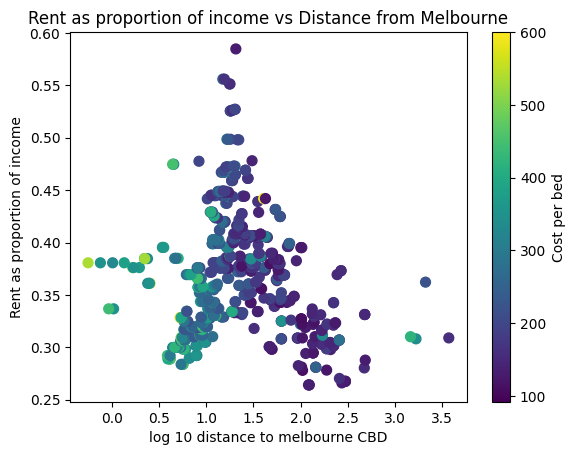

In [605]:
plt.scatter(np.log10(affordability_df['distance_to_melb_cbd_km']), affordability_df['rent as proportion of income'], c=affordability_df['cost per bed'], cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance to melbourne CBD')
plt.ylabel('Rent as proportion of income')

# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Cost per bed')

# adding a title
title = 'Rent as proportion of income vs Distance from Melbourne'
plt.title(title)

# saving the plot
path = f"../plots/{title.replace(' ', '_')}.png"
plt.savefig(path)



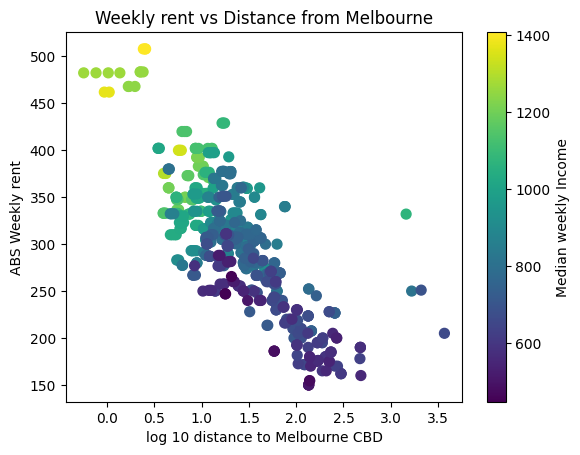

In [412]:
plt.scatter(np.log10(affordability_df['distance_to_melb_cbd_km']), affordability_df['median weekly household rental payment ($) 2021'], c=affordability_df['median equivalised total household income (weekly) ($) 2021'], cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance to Melbourne CBD')
plt.ylabel('ABS Weekly rent')

# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Median weekly Income')

# adding a title
title = 'Weekly rent vs Distance from Melbourne'
plt.title(title)

# saving the plot
path = f"../plots/{title.replace(' ', '_')}.png"
plt.savefig(path)


# I could fit a regression and find the values with the largest  negative residuals


Text(0.5, 1.0, 'Weekly rent vs Distance from Melbourne')

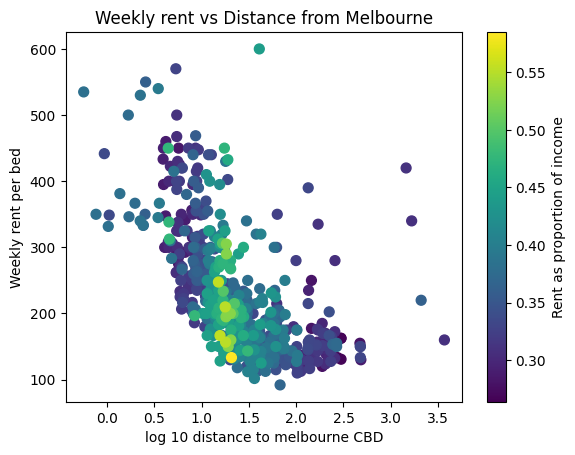

In [599]:
plt.scatter(np.log10(affordability_df['distance_to_melb_cbd_km']), affordability_df['median weekly household rental payment ($) 2021'], c=affordability_df['rent as proportion of income'], cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance to melbourne CBD')
plt.ylabel('Weekly rent per bed')

# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Rent as proportion of income')

# adding a title
title = 'Weekly rent vs Distance from Melbourne'
plt.title(title)

# I could fit a regression and find the values with the largest  negative residuals

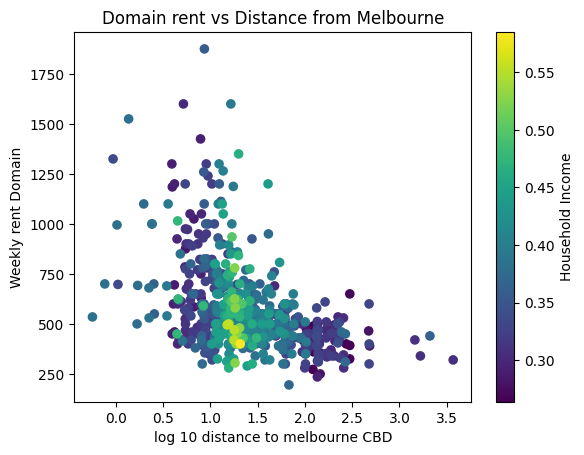

In [595]:

plt.scatter(np.log10(affordability_df['distance_to_melb_cbd_km']), affordability_df['weekly rent amount'], c=affordability_df['rent as proportion of income'],  cmap='viridis', s=35)  # 'viridis' is a colormap
plt.xlabel('log 10 distance to melbourne CBD')
plt.ylabel('Weekly rent Domain')


# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Household Income')

# adding a title
title = 'Domain rent vs Distance from Melbourne'
plt.title(title)

# saving the plot
path = f"../plots/{title.replace(' ', '_')}.png"
plt.savefig(path)


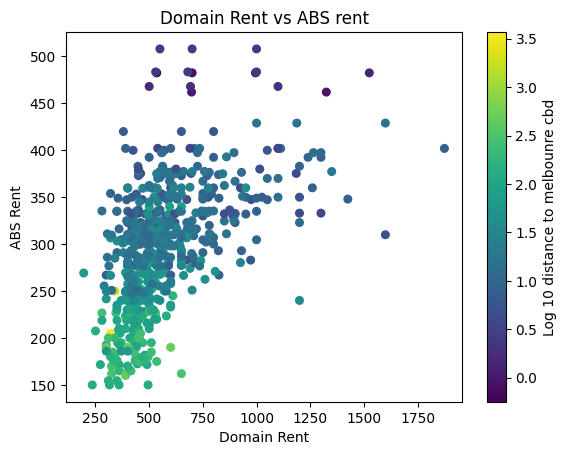

In [591]:
plt.scatter(affordability_df['weekly rent amount'], affordability_df['median weekly household rental payment ($) 2021'], c=np.log10(affordability_df['distance_to_melb_cbd_km']), cmap='viridis', s=30)  # 'viridis' is a colormap
plt.xlabel('Domain Rent')
plt.ylabel('ABS Rent')

# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Log 10 distance to melbounre cbd')

# adding a title
title = 'Domain Rent vs ABS rent'
plt.title(title)

# saving the plot
path = f"../plots/{title.replace(' ', '_')}.png"
plt.savefig(path)


Text(0, 0.5, 'distance_to_melb_cbd_km')

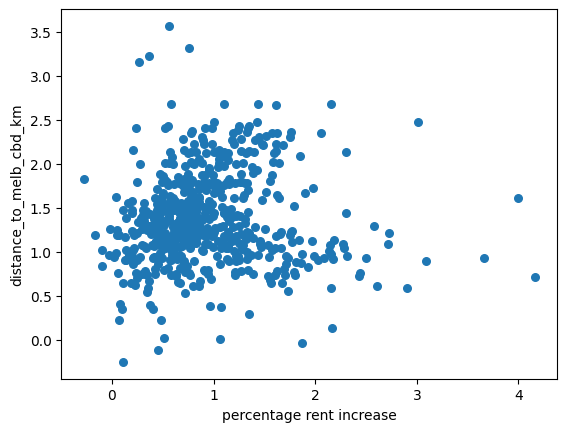

In [416]:
# Distance by percentage increase in price

affordability_df['percentage_increase_price'] = (affordability_df['weekly rent amount'] - affordability_df['median weekly household rental payment ($) 2021']) / affordability_df['median weekly household rental payment ($) 2021']
plt.scatter(affordability_df['percentage_increase_price'], np.log10(affordability_df['distance_to_melb_cbd_km']), s=30)  # 'viridis' is a colormap
plt.xlabel('percentage rent increase')
plt.ylabel('distance_to_melb_cbd_km')


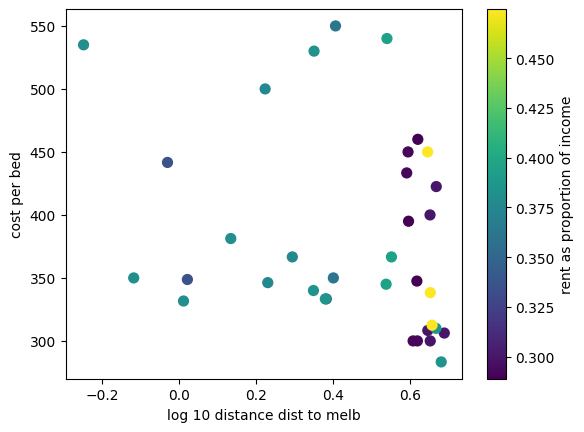

In [597]:
# cost per bedroom
affordability_df['cost per bed'] = affordability_df['weekly rent amount'] / affordability_df['beds']
plt.scatter(np.log10(affordability_5km_df['distance_to_melb_cbd_km']), affordability_5km_df['cost per bed'], c=affordability_5km_df['rent as proportion of income'], cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance dist to melb')
plt.ylabel('cost per bed')

colorbar = plt.colorbar()
colorbar.set_label('rent as proportion of income')

# those low rent as proportion of income and around 0.75 distance ones look ideal to me. 


In [572]:
# Could do cuts of different distances, and then use a linear combination of cost per bed and proportion of income

# i could do current affordability - abs data
# and future affordability - domain data and the increase in rents based upon difference between domain and abs



# distance to public transport will be good,
affordability_5km_df.head(2)

,postcode,beds,weekly rent amount,median weekly household rental payment ($) 2021,median equivalised total household income (weekly) ($) 2021,number of properties,distance_to_melb_cbd_km,average family size (no. of persons) 2021,rent as proportion of income,percentage_increase_price,cost per bed
402,3141,2,695.0,375.333333,1299.333333,94,4.147990,2.433333,0.288866,0.851687,347.5
401,3141,1,460.0,375.333333,1299.333333,57,4.171799,2.433333,0.288866,0.225577,460.0


In [421]:
affordability_df.head(2)

,postcode,beds,weekly rent amount,median weekly household rental payment ($) 2021,median equivalised total household income (weekly) ($) 2021,number of properties,distance_to_melb_cbd_km,average family size (no. of persons) 2021,rent as proportion of income,percentage_increase_price,cost per bed
974,3825,3,360.0,171.666667,650.0,9,123.352326,2.966667,0.264103,1.097087,120.0
975,3825,4,490.0,171.666667,650.0,5,123.026981,2.966667,0.264103,1.854369,122.5


In [574]:
# may want to take the average of each suburb this will be more holistic

"""
This function takes a dataframe of properties joined with all their external features, 
the metrics that will be measured, and the weights for each of these metrics
it returns the most affordable postcodes by number of beds
"""
def most_affordable(affordability_df, metrics, weights):
    z_scores = {}

    # for beds, i have the option to subset before or after the scores are made

    # get the z score for each datapoint over each metric
    for metric, weight in zip(metrics, weights):
        data = affordability_df[metric].values
        data_z_scores = (data - np.mean(data)) / np.std(data)
        z_scores[metric] = weight * data_z_scores


    # Adding the z scores together
    z_score_list = list(z_scores.values())
    sum_z_scores = np.sum(z_score_list, axis=0)
    

    # Finding the postcode with the smallest cumulative z score
    postcodes = affordability_df['postcode'].values
    beds = affordability_df['beds'].values
    number_or_properties = affordability_df['number of properties']
    cost_per_bed = affordability_df['cost per bed']
    rent_proportion_income = affordability_df['rent as proportion of income']
    distance_to_melb_cbd_km = affordability_df['distance_to_melb_cbd_km']
    # Finding the average score for each postcode, over different sized houses
    dataf = pd.DataFrame({'Postcode': postcodes, 'sum_z_scores': sum_z_scores, 'beds': beds, 'number of properties': number_or_properties, 'cost_per_bed': cost_per_bed, 'rent as proportion of income' : rent_proportion_income, 'distance_to_melb_cbd_km': distance_to_melb_cbd_km})
    # df = dataf.groupby('Postcode').agg({'sum_z_scores': 'mean'})

    # Finding the postcode with the smallest aggregated score
    # most_affordable_suburb = df['sum_z_scores'].idxmin()
    
    beds_values = dataf['beds'].unique()
    most_affordable_by_beds = {}

    for num_beds in beds_values:
        bed_data = dataf[dataf['beds'] == num_beds]
        min_row = bed_data[bed_data['sum_z_scores'] == bed_data['sum_z_scores'].min()]
        most_affordable_by_beds[num_beds] = min_row

    
    return most_affordable_by_beds




In [580]:
# the smallest combinations of z scores is the most affordable
affordability_range = {}

distances = [0, 2.5, 5, 10, 15, 20, 35, 50, 70, 100, 150, 200, 500]

affordability_df = affordability_df

for index, distance in enumerate(distances):
    if index < len(distances)-1:

        aff_df = affordability_df[(affordability_df['distance_to_melb_cbd_km'] > distance) & (affordability_df['distance_to_melb_cbd_km'] <= distances[index+1])]
        affordable_suburb = most_affordable(aff_df, ['cost per bed', 'rent as proportion of income'], [0.7, 0.3])
        affordable_suburb = pd.concat(affordable_suburb.values(), ignore_index=True)
        affordability_range[f'{distance}, {distances[index+1]}'] = affordable_suburb

# most_affordable_suburbs = pd.DataFrame(list(affordability_range.items()), columns=['Radius from Melbourne (km)', 'Most Affordable Suburb'])

# Concatenate the DataFrames with a MultiIndex
result_df = pd.concat(affordability_range, axis=1, keys=affordability_range.keys())

affordables = []
for key, value in affordability_range.items():
    value['Distance from Melbourne CBD'] = key
    value.sort_values(['Distance from Melbourne CBD', 'beds'], inplace=True)
    affordables.append(value)

result_df = pd.concat(affordables)

result_df.to_csv(f'../data/curated/most_affordable_suburbs.csv', index=True)


In [581]:
result_df.head()

,Postcode,sum_z_scores,beds,number of properties,cost_per_bed,rent as proportion of income,distance_to_melb_cbd_km,Distance from Melbourne CBD
2,3205,1.048227,1,21,500.000000,0.376105,1.672139,"0, 2.5"
0,3206,-1.089071,2,12,348.750000,0.336735,1.049680,"0, 2.5"
1,3008,-0.784243,3,9,333.333333,0.361052,2.412458,"0, 2.5"
3,3207,0.024704,4,4,381.250000,0.380671,1.361180,"0, 2.5"
1,3181,0.001367,1,33,400.000000,0.299750,4.487956,"2.5, 5"


In [582]:
suburbs = pd.read_csv('../data/curated/sa2_to_postcode/sa2_to_postcode.csv')
suburbs = suburbs[(suburbs['postcode'] >= 3000) & (suburbs['postcode'] < 4000)]

vic_suburbs = suburbs.groupby('postcode')['sa2_name_2021'].agg(lambda x: list(x.unique())).reset_index()

# Rename the columns if needed
vic_suburbs.columns = ['Postcode', 'Suburb']
vic_suburbs['Postcode'] = vic_suburbs['Postcode'].astype(int)

vic_suburbs

,Postcode,Suburb
0,3000,"[North Melbourne, Parkville, Carlton, Melbourn..."
1,3002,[East Melbourne]
2,3003,"[North Melbourne, West Melbourne - Residential..."
3,3004,"[Albert Park, East Melbourne, South Melbourne,..."
4,3006,"[South Melbourne, Port Melbourne Industrial, S..."
...,...,...
689,3990,[Wonthaggi - Inverloch]
690,3991,[Wonthaggi - Inverloch]
691,3992,[Wonthaggi - Inverloch]
692,3995,[Wonthaggi - Inverloch]


In [583]:
joined_df = result_df.merge(vic_suburbs, on='Postcode', how='left')
joined_df.reset_index(inplace=True)

joined_df.set_index(['Distance from Melbourne CBD', 'beds'], inplace=True)
joined_df.drop(columns=['index', 'Postcode'])
joined_df.to_csv(f'../data/curated/most_affordable_suburbs.csv', index=True)





In [1]:

# https://captainfi.com/cost-driving-work/#:~:text=Excluding%20the%20cost%20of%20the,this%20figure%20of%20course%20increases.
